<a href="https://colab.research.google.com/github/rajasimhasiddarth9/python-data-science-fundamentals/blob/main/module5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
# Data Science Mini Project
## Student Performance Analysis

### Objective
#To analyze student performance using a real-world dataset
#and identify patterns related to study time, absences,
#previous grades, and final examination results.

### Tools Used
#Pandas and NumPy
# Matplotlib and Seaborn

### Project Workflow
1.# Load the dataset
2. #Explore and clean the data
3.# Perform exploratory data analysis
4. #Create visualizations
5. #Identify key findings

5.0

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile
import urllib.request

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [13]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00320/student.zip"

urllib.request.urlretrieve(url, "student.zip")

with zipfile.ZipFile("student.zip", "r") as zip_file:
    with zip_file.open("student-mat.csv") as file:
        df = pd.read_csv(file, sep=";")

print("Dataset loaded successfully!")
df.head()

Dataset loaded successfully!


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [14]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe())

Dataset shape: (395, 33)

Column names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


In [15]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nFinal grade distribution:")
print(df["G3"].describe())


Missing values:
school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

Duplicate rows: 0

Final grade distribution:
count    395.000000
mean      10.415190
std        4.581443
min        0.000000
25%        8.000000
50%       11.000000
75%       14.000000
max       20.000000
Name: G3, dtype: float64


In [16]:
df_clean = df.copy()

# Remove duplicate rows if any exist
df_clean = df_clean.drop_duplicates()

# Check missing values again
print("Missing values after cleaning:")
print(df_clean.isnull().sum())

print("\nCleaned dataset shape:", df_clean.shape)

Missing values after cleaning:
school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

Cleaned dataset shape: (395, 33)


In [17]:
print("Average final grade:", round(df_clean["G3"].mean(), 2))
print("Highest final grade:", df_clean["G3"].max())
print("Lowest final grade:", df_clean["G3"].min())
print("Median final grade:", df_clean["G3"].median())

Average final grade: 10.42
Highest final grade: 20
Lowest final grade: 0
Median final grade: 11.0


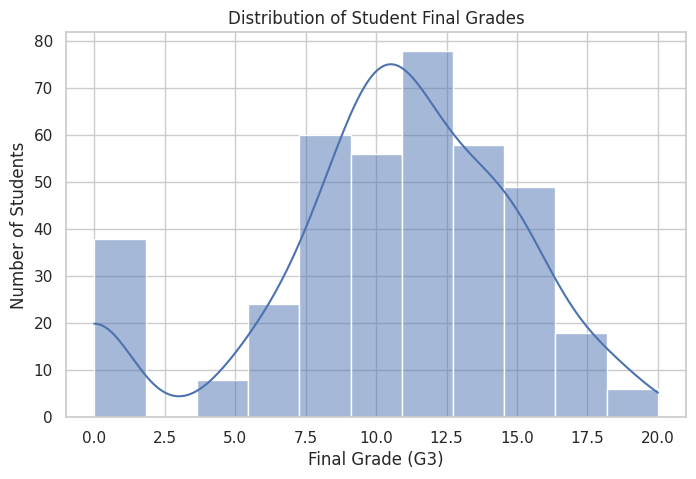

In [18]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df_clean, x="G3", bins=11, kde=True)

plt.title("Distribution of Student Final Grades")
plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")
plt.show()

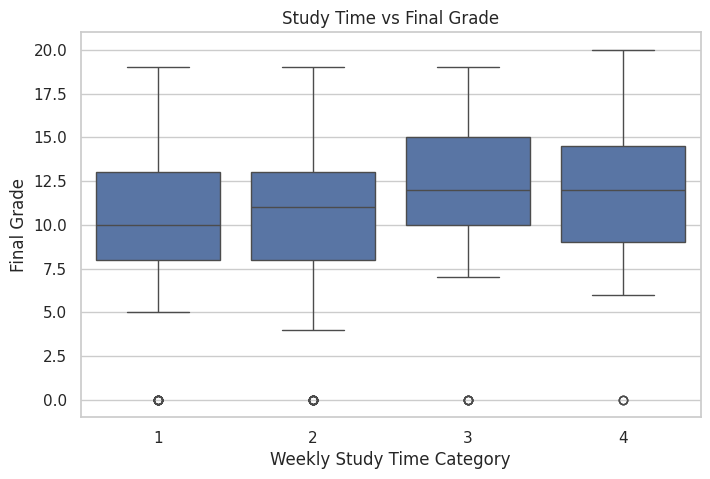

In [19]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df_clean, x="studytime", y="G3")

plt.title("Study Time vs Final Grade")
plt.xlabel("Weekly Study Time Category")
plt.ylabel("Final Grade")
plt.show()

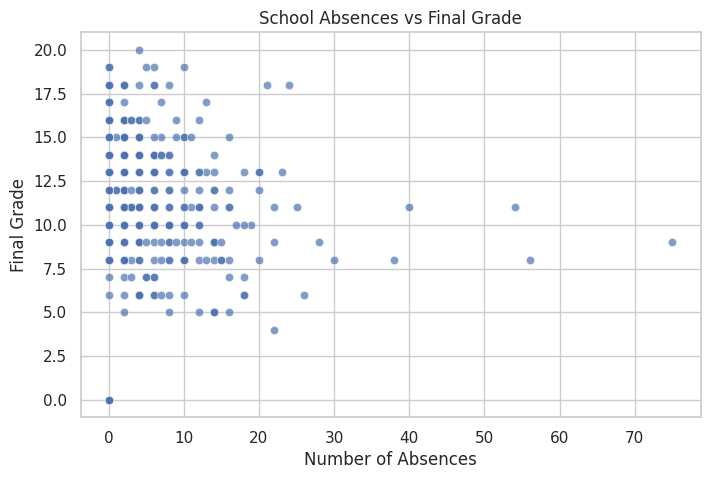

In [20]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_clean,
    x="absences",
    y="G3",
    alpha=0.7
)

plt.title("School Absences vs Final Grade")
plt.xlabel("Number of Absences")
plt.ylabel("Final Grade")
plt.show()

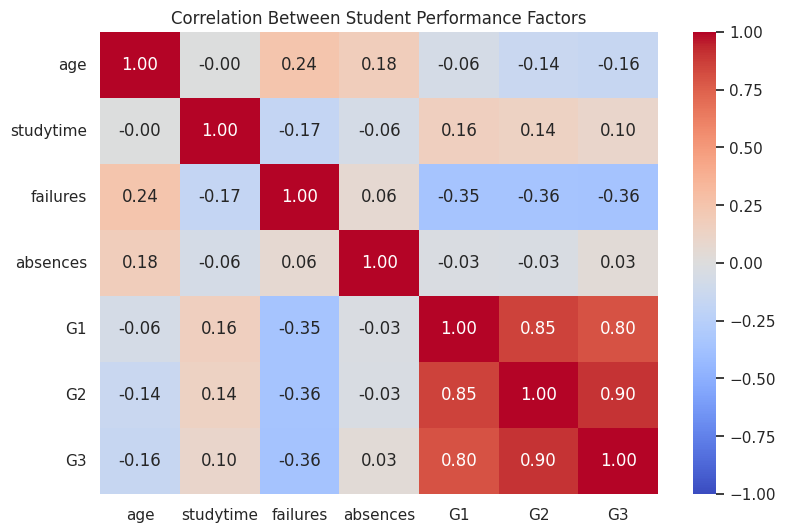

In [21]:
numeric_cols = [
    "age", "studytime", "failures",
    "absences", "G1", "G2", "G3"
]

correlation = df_clean[numeric_cols].corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Student Performance Factors")
plt.show()

In [22]:
study_analysis = (
    df_clean.groupby("studytime")["G3"]
    .agg(["mean", "median", "count"])
    .round(2)
)

study_analysis.columns = [
    "Average Grade", "Median Grade", "Number of Students"
]

display(study_analysis)

,Average Grade,Median Grade,Number of Students
studytime,,,
1,10.05,10.0,105
2,10.17,11.0,198
3,11.40,12.0,65
4,11.26,12.0,27


In [23]:
highest_grade = df_clean["G3"].max()
lowest_grade = df_clean["G3"].min()
average_grade = df_clean["G3"].mean()

study_means = df_clean.groupby("studytime")["G3"].mean()
best_study_category = study_means.idxmax()
lowest_study_category = study_means.idxmin()

print("KEY FINDINGS")
print("-" * 40)

print(f"Number of students analyzed: {len(df_clean)}")
print(f"Average final grade: {average_grade:.2f}/20")
print(f"Highest final grade: {highest_grade}/20")
print(f"Lowest final grade: {lowest_grade}/20")

print(
    f"Study-time category with highest average grade: "
    f"{best_study_category}"
)

print(
    f"Study-time category with lowest average grade: "
    f"{lowest_study_category}"
)

KEY FINDINGS
----------------------------------------
Number of students analyzed: 395
Average final grade: 10.42/20
Highest final grade: 20/20
Lowest final grade: 0/20
Study-time category with highest average grade: 3
Study-time category with lowest average grade: 1


In [24]:
df_clean.to_csv("student_performance_cleaned.csv", index=False)

print("Cleaned dataset exported successfully!")

Cleaned dataset exported successfully!


In [25]:
from google.colab import files

files.download("student_performance_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Conclusion

#In this mini project, I analyzed a real-world Student Performance
#dataset using Python, Pandas, NumPy, Matplotlib, and Seaborn.

#I explored the dataset, checked for missing values and duplicates,
#calculated summary statistics, and created visualizations to study
#the distribution of grades and relationships between study time,
#absences, previous grades, and final grades.

#The analysis helped me practice exploratory data analysis (EDA)
#and understand how visualizations and summary statistics can
#turn raw data into useful insights.

#The findings describe patterns in this dataset and do not
#necessarily establish cause-and-effect relationships.